<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 1 - Importing the libraries and loading the files</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Importing the libraries</h3>
</div>

In [1]:
#Importing the Pandas and Matplotlib libraries
import pandas as pd
import matplotlib.pyplot as plt

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Loading the files</h3>
</div>

In [2]:
#Importing the population.csv file
population = pd.read_csv('../data/population.csv')

#Importing the dispo_alimentaire.csv file
dispo_alimentaire = pd.read_csv('../data/dispo_alimentaire.csv')

#Importing the aide_alimentaire.csv file
aide_alimentaire = pd.read_csv('../data/aide_alimentaire.csv')

#Importing the sous_nutrition.csv file
sous_nutrition = pd.read_csv('../data/sous_nutrition.csv')

Harmonising country names: the food availability file writes `Royaume-Uni` and `Tchéquie (la)`, while the population and undernourishment files use the full names, and the food aid file uses the former name `Swaziland` for Eswatini. Without this step, these countries disappear from the joins.

In [3]:
#Harmonising the country names so that every country is found in the joins
dispo_alimentaire['Zone'] = dispo_alimentaire['Zone'].replace({
    'Royaume-Uni': "Royaume-Uni de Grande-Bretagne et d'Irlande du Nord",
    'Tchéquie (la)': 'Tchéquie',
})
aide_alimentaire['Pays bénéficiaire'] = aide_alimentaire['Pays bénéficiaire'].replace({'Swaziland': 'Eswatini'})

#Check: every country of the food availability file now exists in the population file
print(sorted(set(dispo_alimentaire['Zone']) - set(population['Zone'])))

[]


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 2 - Exploratory analysis of the files</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Exploratory analysis of the population file</h3>
</div>

In [4]:
#Displaying the dimensions of the dataset
print("The table has {} rows.".format(population.shape[0]))
print("The table has {} columns.".format(population.shape[1]))

The table has 1416 rows.
The table has 3 columns.


In [5]:
#Checking the number of columns
#The type of data in each column
#The number of values in each column
population.info()

<class 'pandas.DataFrame'>
RangeIndex: 1416 entries, 0 to 1415
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Zone    1416 non-null   str    
 1   Année   1416 non-null   int64  
 2   Valeur  1416 non-null   float64
dtypes: float64(1), int64(1), str(1)
memory usage: 33.3 KB


In [6]:
#Displaying the first 5 rows of the table
population.head(5)

,Zone,Année,Valeur
0,Afghanistan,2013,32269.589
1,Afghanistan,2014,33370.794
2,Afghanistan,2015,34413.603
3,Afghanistan,2016,35383.032
4,Afghanistan,2017,36296.113


In [7]:
#We harmonise the units: the population is given in thousands, so we multiply it by 1000
#Multiplying the Valeur column by 1000
population['Valeur'] = population['Valeur'] * 1000

In [8]:
#Renaming the Valeur column to Population
population = population.rename(columns={'Valeur':'Population'})

In [9]:
#Displaying the first 5 rows of the table to check the changes
#Converting the population column from float to int
population['Population'] = population['Population'].astype(int)
population.head(5)

,Zone,Année,Population
0,Afghanistan,2013,32269589
1,Afghanistan,2014,33370794
2,Afghanistan,2015,34413603
3,Afghanistan,2016,35383032
4,Afghanistan,2017,36296113


In [10]:
#Finding the time frame of the dataset
année_min_population = population['Année'].min()
année_max_population = population['Année'].max()
print(f"The dataset starts in {année_min_population}.")
print(f"The dataset ends in {année_max_population}.")

The dataset starts in 2013.
The dataset ends in 2018.


In [11]:
#Finding the number of countries listed in the Zone column
nombre_pays_population = population['Zone'].nunique()
print(f"There are {nombre_pays_population} countries listed in the population dataset.")


There are 236 countries listed in the population dataset.


Conclusion:
The population dataset has 1,416 rows and 3 columns and gives the population of 236 countries between 2013 and 2018.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Exploratory analysis of the food availability file</h3>
</div>

In [12]:
#Displaying the dimensions of the dataset
print("The table has {} rows.".format(dispo_alimentaire.shape[0]))
print("The table has {} columns.".format(dispo_alimentaire.shape[1]))


The table has 15605 rows.
The table has 18 columns.


In [13]:
#Checking the number of columns
#The type of data in each column
#The number of values in each column
dispo_alimentaire.info()

<class 'pandas.DataFrame'>
RangeIndex: 15605 entries, 0 to 15604
Data columns (total 18 columns):
 #   Column                                                         Non-Null Count  Dtype  
---  ------                                                         --------------  -----  
 0   Zone                                                           15605 non-null  str    
 1   Produit                                                        15605 non-null  str    
 2   Origine                                                        15605 non-null  str    
 3   Aliments pour animaux                                          2720 non-null   float64
 4   Autres Utilisations                                            5496 non-null   float64
 5   Disponibilité alimentaire (Kcal/personne/jour)                 14241 non-null  float64
 6   Disponibilité alimentaire en quantité (kg/personne/an)         14015 non-null  float64
 7   Disponibilité de matière grasse en quantité (g/personne/jour)  11794 

In [14]:
#Displaying the first 5 rows of the table
dispo_alimentaire.head(5)

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53.0,NaN,NaN,53.0,NaN,53.0,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41.0,2.0,40.0,39.0,2.0,3.0,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82.0,NaN,82.0,82.0,NaN,NaN,NaN,NaN,NaN


In [15]:
#Replacing the NaN in the dataset with 0
dispo_alimentaire = dispo_alimentaire.fillna(0)

In [16]:
#Multiplying every column given in thousands of tonnes by 1000, to get tonnes
colonnes_kg = ['Aliments pour animaux', 'Autres Utilisations', 'Disponibilité intérieure', 'Exportations - Quantité', 'Importations - Quantité',
                'Nourriture', 'Pertes', 'Production', 'Semences', 'Traitement', 'Variation de stock']
dispo_alimentaire[colonnes_kg] = dispo_alimentaire[colonnes_kg] * 1000

In [17]:
dispo_alimentaire.head(5)

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,0.0,0.0,5.0,1.72,0.20,0.77,53000.0,0.0,0.0,53000.0,0.0,53000.0,0.0,0.0,0.0
1,Afghanistan,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,0.02,41000.0,2000.0,40000.0,39000.0,2000.0,3000.0,0.0,0.0,0.0
2,Afghanistan,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,0.03,2000.0,0.0,2000.0,2000.0,0.0,0.0,0.0,0.0,0.0
3,Afghanistan,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Afghanistan,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,0.05,82000.0,0.0,82000.0,82000.0,0.0,0.0,0.0,0.0,0.0


In [18]:
#Finding the number of countries listed in the Zone column
nombre_pays_disponibilité_alimentaire = dispo_alimentaire['Zone'].nunique()
print(f"There are {nombre_pays_disponibilité_alimentaire} countries listed in the food availability dataset.")

There are 174 countries listed in the food availability dataset.


Conclusion:
The food availability dataset focuses on the year 2017. It has 15,605 rows and 18 columns and covers 174 countries. It details food availability by country, makes it possible to measure nutritional intake and to classify products by origin. It also describes how food is used.


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Exploratory analysis of the food aid file</h3>
</div>

In [19]:
#Displaying the dimensions of the dataset
print("The table has {} rows.".format(aide_alimentaire.shape[0]))
print("The table has {} columns.".format(aide_alimentaire.shape[1]))

The table has 1475 rows.
The table has 4 columns.


In [20]:
#Checking the number of columns
#The type of data in each column
#The number of values in each column
aide_alimentaire.info()

<class 'pandas.DataFrame'>
RangeIndex: 1475 entries, 0 to 1474
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Pays bénéficiaire  1475 non-null   str  
 1   Année              1475 non-null   int64
 2   Produit            1475 non-null   str  
 3   Valeur             1475 non-null   int64
dtypes: int64(2), str(2)
memory usage: 46.2 KB


In [21]:
#Displaying the first 5 rows of the table
aide_alimentaire.head(5)

,Pays bénéficiaire,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224
3,Afghanistan,2014,Blé et Farin,15160
4,Afghanistan,2013,Céréales,40504


In [22]:
#Renaming the Pays bénéficiaire column to Zone
aide_alimentaire = aide_alimentaire.rename(columns={'Pays bénéficiaire':'Zone'})

In [23]:
#Renaming the Valeur column to Aide alimentaire
#Multiplying the Aide alimentaire column, given in tonnes, by 1000 to get kg
aide_alimentaire = aide_alimentaire.rename(columns={'Valeur':'Aide alimentaire'})
aide_alimentaire['Aide alimentaire'] = aide_alimentaire['Aide alimentaire'] * 1000


In [24]:
#Displaying the first 5 rows of the table
aide_alimentaire.head(5)

,Zone,Année,Produit,Aide alimentaire
0,Afghanistan,2013,Autres non-céréales,682000
1,Afghanistan,2014,Autres non-céréales,335000
2,Afghanistan,2013,Blé et Farin,39224000
3,Afghanistan,2014,Blé et Farin,15160000
4,Afghanistan,2013,Céréales,40504000


In [25]:
#Finding the time frame of the dataset and the number of countries listed
année_min_aide_alimentaire = aide_alimentaire['Année'].min()
année_max_aide_alimentaire = aide_alimentaire['Année'].max()
nombre_pays_aide_alimentaire = aide_alimentaire['Zone'].nunique()
print(f"There are {nombre_pays_aide_alimentaire} countries listed in the food aid dataset.")
print(f"The dataset starts in {année_min_aide_alimentaire}.")
print(f"The dataset ends in {année_max_aide_alimentaire}.")

There are 76 countries listed in the food aid dataset.
The dataset starts in 2013.
The dataset ends in 2016.


Conclusion:
The food aid dataset has 1,475 rows and 4 columns. It details the quantity of food aid, in kilograms, received by 76 countries between 2013 and 2016.


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.4 - Exploratory analysis of the undernourishment file</h3>
</div>

In [26]:
#Displaying the dimensions of the dataset
print("The table has {} rows.".format(sous_nutrition.shape[0]))
print("The table has {} columns.".format(sous_nutrition.shape[1]))

The table has 1218 rows.
The table has 3 columns.


In [27]:
#Checking the number of columns
#The type of data in each column
#The number of values in each column
sous_nutrition.info()

<class 'pandas.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Zone    1218 non-null   str  
 1   Année   1218 non-null   str  
 2   Valeur  624 non-null    str  
dtypes: str(3)
memory usage: 28.7 KB


In [28]:
#Displaying the first 5 rows of the table
sous_nutrition.head(5)

,Zone,Année,Valeur
0,Afghanistan,2012-2014,8.6
1,Afghanistan,2013-2015,8.8
2,Afghanistan,2014-2016,8.9
3,Afghanistan,2015-2017,9.7
4,Afghanistan,2016-2018,10.5


In [29]:
#Renaming the Valeur column to Sous nutrition
sous_nutrition = sous_nutrition.rename(columns={'Valeur':'Sous nutrition'})

In [30]:
#Converting the column (errors=coerce automatically turns the rows that are not numbers into NaN)
#Then replacing the NaN with 0
sous_nutrition['Sous nutrition'] = pd.to_numeric(sous_nutrition['Sous nutrition'], errors='coerce')
sous_nutrition = sous_nutrition.fillna(0)


In [31]:
#Multiplying the Sous nutrition column by 1000000
sous_nutrition['Sous nutrition'] = sous_nutrition['Sous nutrition'] * 1000000
#Converting the Sous nutrition column from float to int
sous_nutrition['Sous nutrition'] = sous_nutrition['Sous nutrition'].astype(int)

In [32]:
#Displaying the first 5 rows of the table
sous_nutrition.head(5)

,Zone,Année,Sous nutrition
0,Afghanistan,2012-2014,8600000
1,Afghanistan,2013-2015,8800000
2,Afghanistan,2014-2016,8900000
3,Afghanistan,2015-2017,9700000
4,Afghanistan,2016-2018,10500000


In [33]:
#Finding the time frame of the dataset and the number of countries listed
année_min_sous_nutrition = sous_nutrition['Année'].min()
année_max_sous_nutrition = sous_nutrition['Année'].max()
nombre_pays_sous_nutrition = sous_nutrition['Zone'].nunique()
print(f"There are {nombre_pays_sous_nutrition} countries listed in the undernourishment dataset.")
print(f"The first period of the dataset is {année_min_sous_nutrition}.")
print(f"The last period of the dataset is {année_max_sous_nutrition}.")

There are 203 countries listed in the undernourishment dataset.
The first period of the dataset is 2012-2014.
The last period of the dataset is 2017-2019.


Conclusion:
The undernourishment dataset has 1,218 rows and 3 columns. It lists 203 countries and gives the number of undernourished people per country, as three-year averages from 2012-2014 to 2017-2019.


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.1 - Share of undernourished people</h3>
</div>

In [34]:
#Filtering the population and sous_nutrition tables on the year 2017
sous_nutrition_2017 = sous_nutrition[sous_nutrition['Année'] == '2016-2018']
population_2017 = population[population['Année'] == 2017]

In [35]:
#First, we join the population table and the undernourishment table, for the year 2017
population_sous_nutrition_2017_join = pd.merge(population_2017, sous_nutrition_2017, on='Zone', how='inner')

In [36]:
#Displaying the dataset
population_sous_nutrition_2017_join.head(5)

,Zone,Année_x,Population,Année_y,Sous nutrition
0,Afghanistan,2017,36296113,2016-2018,10500000
1,Afrique du Sud,2017,57009756,2016-2018,3100000
2,Albanie,2017,2884169,2016-2018,100000
3,Algérie,2017,41389189,2016-2018,1300000
4,Allemagne,2017,82658409,2016-2018,0


In [37]:
#Computing and displaying the number of undernourished people
sous_nutrition_mondial_2017 = population_sous_nutrition_2017_join['Sous nutrition'].sum()
print(f"The total number of undernourished people in 2017 is: {sous_nutrition_mondial_2017 :,}")

The total number of undernourished people in 2017 is: 535,700,000


In [38]:
#Computing the world population in 2017
population_mondial_2017 = population_sous_nutrition_2017_join['Population'].sum()
print(f"In 2017, the world population was {population_mondial_2017 :,}")

In 2017, the world population was 7,543,798,769


In [39]:
#Computing the percentage of undernourished people
sous_nutriton_2017_repartition = (sous_nutrition_mondial_2017/population_mondial_2017)*100
print(f"The percentage of undernourished people in 2017 was {sous_nutriton_2017_repartition:.2f} % ")

The percentage of undernourished people in 2017 was 7.10 % 


Conclusion:
In 2017, the world population was 7.5 billion. 535 million people suffered from undernourishment, 7.10% of the world population, or one person in 14.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.2 - Theoretical number of people who could be fed</h3>
</div>

In [40]:
#How much does a human being eat on average? Source => https://www.fao.org/4/x5643f/x5643f00.htm#Contents
#Chapter 1, section B3: "2,300 to 2,500 calories, provided by 700 to 750 g of cereals, are enough for a person to live each day"
calorie_moy = int((2300+2500)/2)
print(f"The average daily number of calories a human being needs is {calorie_moy}")

The average daily number of calories a human being needs is 2400


In [41]:
#We start by joining the population and Dispo_alimentaire data frames, to add the population to the latter
dispo_alimentaire_population_2017_join = pd.merge(population_2017, dispo_alimentaire , on='Zone', how='left')

In [42]:
#Computing the kcal available per Zone and creating the kcal par pays column
dispo_alimentaire_population_2017_join['kcal par pays'] = (
    dispo_alimentaire_population_2017_join['Disponibilité alimentaire (Kcal/personne/jour)']
    * dispo_alimentaire_population_2017_join['Population']
    *365
)

In [43]:
#Displaying the dataset with the new kcal par pays column
dispo_alimentaire_population_2017_join.head(5)

,Zone,Année,Population,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),...,Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock,kcal par pays
0,Afghanistan,2017,36296113,Abats Comestible,animale,0.0,0.0,5.0,1.72,0.20,...,53000.0,0.0,0.0,53000.0,0.0,53000.0,0.0,0.0,0.0,6.624041e+10
1,Afghanistan,2017,36296113,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,...,41000.0,2000.0,40000.0,39000.0,2000.0,3000.0,0.0,0.0,0.0,1.324808e+10
2,Afghanistan,2017,36296113,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,...,2000.0,0.0,2000.0,2000.0,0.0,0.0,0.0,0.0,0.0,1.324808e+10
3,Afghanistan,2017,36296113,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00
4,Afghanistan,2017,36296113,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,...,82000.0,0.0,82000.0,82000.0,0.0,0.0,0.0,0.0,0.0,5.299232e+10


In [44]:
#Computing the kcal available worldwide
dispo_kcal = dispo_alimentaire_population_2017_join['kcal par pays'].sum()
print(f"World total: {int(dispo_kcal):,} calories over the year 2017")

World total: 7,731,489,394,689,605 calories over the year 2017


In [45]:
#Computing the number of people who could be fed
humains_nourris = int((dispo_kcal/calorie_moy)/365)
print(f" Based on the calories available worldwide, {humains_nourris :,} people could be fed")

 Based on the calories available worldwide, 8,825,901,135 people could be fed


Conclusion:
Based on the calories available worldwide, 8.8 billion people should be able to meet their needs and eat properly, about 1.3 billion more than the world population at the time. Yet about 535 million people suffer from undernourishment.
World resources are therefore very poorly managed and unevenly shared.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.3 - Theoretical number of people who could be fed with plant products</h3>
</div>

In [46]:
#Moving the plant product data into a new dataframe
dispo_alimentaire_vegetaux = dispo_alimentaire_population_2017_join[dispo_alimentaire_population_2017_join['Origine'] == 'vegetale'].copy()
dispo_alimentaire_vegetaux.head(10)

,Zone,Année,Population,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),...,Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock,kcal par pays
1,Afghanistan,2017,36296113,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,...,41000.0,2000.0,40000.0,39000.0,2000.0,3000.0,0.0,0.0,0.0,1.324808e+10
2,Afghanistan,2017,36296113,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,...,2000.0,0.0,2000.0,2000.0,0.0,0.0,0.0,0.0,0.0,1.324808e+10
3,Afghanistan,2017,36296113,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00
4,Afghanistan,2017,36296113,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,...,82000.0,0.0,82000.0,82000.0,0.0,0.0,0.0,0.0,0.0,5.299232e+10
6,Afghanistan,2017,36296113,Bière,vegetale,0.0,0.0,0.0,0.09,0.00,...,3000.0,0.0,3000.0,3000.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00
7,Afghanistan,2017,36296113,Blé,vegetale,0.0,0.0,1369.0,160.23,4.69,...,5992000.0,0.0,1173000.0,4895000.0,775000.0,5169000.0,322000.0,0.0,-350000.0,1.813662e+13
8,Afghanistan,2017,36296113,Boissons Alcooliques,vegetale,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00
9,Afghanistan,2017,36296113,Café,vegetale,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00
10,Afghanistan,2017,36296113,Coco (Incl Coprah),vegetale,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00
12,Afghanistan,2017,36296113,"Céréales, Autres",vegetale,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00


In [47]:
#Computing the number of kcal available from plant products
vegetaux_kcal = dispo_alimentaire_vegetaux['kcal par pays'].sum()
print(f"World total of calories available from plant products: {int(vegetaux_kcal):,} ")

World total of calories available from plant products: 6,369,070,931,881,840 


In [48]:
#Computing the number of people who could be fed with plant products
humains_nourris_vegetaux = int((vegetaux_kcal/calorie_moy)/365)
print(f" Plant products could feed {humains_nourris_vegetaux :,} people")

 Plant products could feed 7,270,628,917 people


In [49]:
#Share of people who could be fed with plant products
proportion_humains_nourris_par_vegetaux = (humains_nourris_vegetaux/population_mondial_2017)*100
print(f"Plant products could feed {proportion_humains_nourris_par_vegetaux:.2f} % of the world population.")

Plant products could feed 96.38 % of the world population.


Conclusion:
Plant products, which total about 6,400 million billion calories, would almost be enough on their own to feed the world population, covering 96% of it.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.4 - Use of domestic supply</h3>
</div>

In [50]:
#Computing the total domestic supply
disponibilité_total = dispo_alimentaire['Disponibilité intérieure'].sum()
print(f"Total domestic supply is {int(disponibilité_total):,} tonnes")

Total domestic supply is 9,848,994,000 tonnes


In [51]:
#Creating a for loop to display the values of the animal feed, losses, food... columns
disponibilité_boucle = ['Aliments pour animaux', 'Pertes', 'Nourriture', 'Semences', 'Traitement', 'Autres Utilisations']

for colonne in disponibilité_boucle:
    total = dispo_alimentaire[colonne].sum()

    print(f"{colonne} : {int(total):,} tonnes, or {(total/disponibilité_total)*100:.2f} % of total domestic supply")

Aliments pour animaux : 1,304,245,000 tonnes, or 13.24 % of total domestic supply
Pertes : 453,698,000 tonnes, or 4.61 % of total domestic supply
Nourriture : 4,876,258,000 tonnes, or 49.51 % of total domestic supply
Semences : 154,681,000 tonnes, or 1.57 % of total domestic supply
Traitement : 2,204,687,000 tonnes, or 22.38 % of total domestic supply
Autres Utilisations : 865,023,000 tonnes, or 8.78 % of total domestic supply


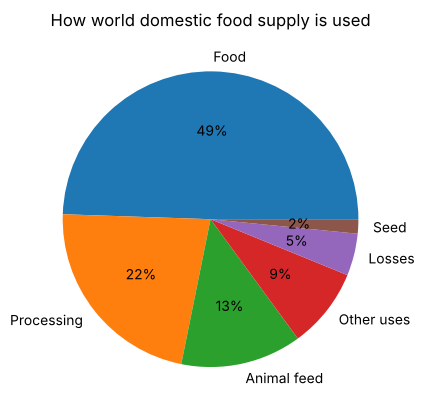

In [52]:
repartition_dispo_alimentaire_mondiale = {'Food': 49.51, 'Processing': 22.38, 'Animal feed': 13.24,
                                           'Other uses': 8.78, 'Losses': 4.61, 'Seed': 1.57}
repartition_dispo_alimentaire_mondiale_series = pd.Series(repartition_dispo_alimentaire_mondiale)
repartition_dispo_alimentaire_mondiale_series.plot.pie(
    autopct='%1.0f%%'
)
plt.title("How world domestic food supply is used");

Conclusion:
Food accounts for 49% of world domestic food supply. Processing (transforming a raw product) and animal feed together account for 35%.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.5 - Use of cereals</h3>
</div>

In [53]:
#Creating a list with all the cereals
céréales_liste = ['Blé','Céréales, Autres', 'Maïs','Millet', 'Orge', 'Riz (Eq Blanchi)', 'Avoine', 'Seigle', 'Sorgho']

In [54]:
#Creating a dataframe with the information for these cereals only
dataframe_céréales = dispo_alimentaire_vegetaux[dispo_alimentaire_vegetaux['Produit'].isin(céréales_liste)]

In [55]:
#Computing the total domestic supply of cereals
total_dispo_céréale = dataframe_céréales['Disponibilité intérieure'].sum()

In [56]:
#Displaying the share used for animal feed
céréales_alimentation_animale = dataframe_céréales['Aliments pour animaux'].sum()
proportion_alimentation_animale = (céréales_alimentation_animale/total_dispo_céréale)*100
print(f"Animal feed uses {proportion_alimentation_animale:.2f} % of world cereal supply")

Animal feed uses 36.29 % of world cereal supply


In [57]:
#Displaying the share used for human food
céréales_alimentation_humaine = dataframe_céréales['Nourriture'].sum()
proportion_alimentation_humaine = (céréales_alimentation_humaine/total_dispo_céréale)*100
print(f"Human food uses {proportion_alimentation_humaine:.2f} % of world cereal supply")

Human food uses 42.75 % of world cereal supply


In [58]:
#Displaying the share used as seed
céréales_semences = dataframe_céréales['Semences'].sum()
proportion_semences = (céréales_semences/total_dispo_céréale)*100
print(f"Agriculture (seed) uses {proportion_semences:.2f} % of world cereal supply")

Agriculture (seed) uses 2.85 % of world cereal supply


In [59]:
#Displaying the share of losses
céréales_pertes = dataframe_céréales['Pertes'].sum()
proportion_pertes = (céréales_pertes/total_dispo_céréale)*100
print(f"Losses account for {proportion_pertes:.2f} % of world cereal supply")

Losses account for 4.45 % of world cereal supply


In [60]:
#Displaying the share of industrial processing
céréales_traitement = dataframe_céréales['Traitement'].sum()
proportion_traitement = (céréales_traitement/total_dispo_céréale)*100
print(f"Industrial processing accounts for {proportion_traitement:.2f} % of world cereal supply")

Industrial processing accounts for 3.93 % of world cereal supply


In [61]:
#Displaying the share of other uses
céréales_autres_utilisations = dataframe_céréales['Autres Utilisations'].sum()
proportion_autres_utilisations = (céréales_autres_utilisations/total_dispo_céréale)*100
print(f"Other uses account for {proportion_autres_utilisations:.2f} % of world cereal supply")

Other uses account for 9.75 % of world cereal supply


Text(0.5, 1.0, 'How cereals are used worldwide')

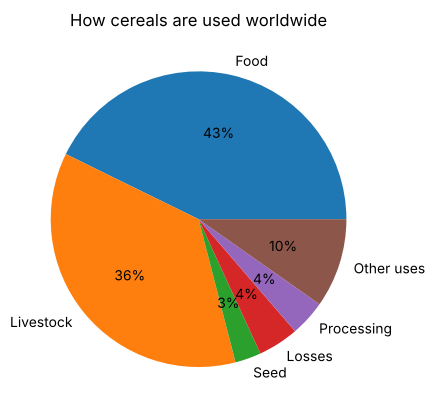

In [62]:
#Creating a pie chart to show how cereals are used worldwide
proportions_céréales_dict = {'Food': proportion_alimentation_humaine, 'Livestock': proportion_alimentation_animale,
                             'Seed': proportion_semences, 'Losses': proportion_pertes, 'Processing': proportion_traitement,
                             'Other uses': proportion_autres_utilisations}
proportions_céréales_series = pd.Series(proportions_céréales_dict)
proportions_céréales_series.plot.pie(
    autopct='%1.0f%%'
)
plt.title("How cereals are used worldwide")

Conclusion:
Food also dominates the use of cereals worldwide, with 43%. Livestock farming, or animal feed, however, takes a much larger share here, with 36%. Meat consumption requires more than a third of the cereals available worldwide.


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.6 - Countries with the highest share of undernourished people in 2017</h3>
</div>

In [63]:
#Creating the share-per-country column
population_sous_nutrition_2017_join['Proportion %'] = (
    population_sous_nutrition_2017_join['Sous nutrition']
    / population_sous_nutrition_2017_join['Population']
    *100
)

In [64]:
#Displaying the new dataset with the share column
population_sous_nutrition_2017_join.head(5)

,Zone,Année_x,Population,Année_y,Sous nutrition,Proportion %
0,Afghanistan,2017,36296113,2016-2018,10500000,28.928718
1,Afrique du Sud,2017,57009756,2016-2018,3100000,5.437666
2,Albanie,2017,2884169,2016-2018,100000,3.467203
3,Algérie,2017,41389189,2016-2018,1300000,3.140917
4,Allemagne,2017,82658409,2016-2018,0,0.000000


In [65]:
#Displaying the 10 worst countries after sorting
population_sous_nutrition_2017_join = population_sous_nutrition_2017_join.sort_values(by='Proportion %', ascending=False)
population_sous_nutrition_2017_join.head(10)

,Zone,Année_x,Population,Année_y,Sous nutrition,Proportion %
78,Haïti,2017,10982366,2016-2018,5300000,48.259182
157,République populaire démocratique de Corée,2017,25429825,2016-2018,12000000,47.188685
108,Madagascar,2017,25570512,2016-2018,10500000,41.062924
103,Libéria,2017,4702226,2016-2018,1800000,38.279742
100,Lesotho,2017,2091534,2016-2018,800000,38.249438
183,Tchad,2017,15016753,2016-2018,5700000,37.957606
161,Rwanda,2017,11980961,2016-2018,4200000,35.055619
121,Mozambique,2017,28649018,2016-2018,9400000,32.810898
186,Timor-Leste,2017,1243258,2016-2018,400000,32.173531
0,Afghanistan,2017,36296113,2016-2018,10500000,28.928718


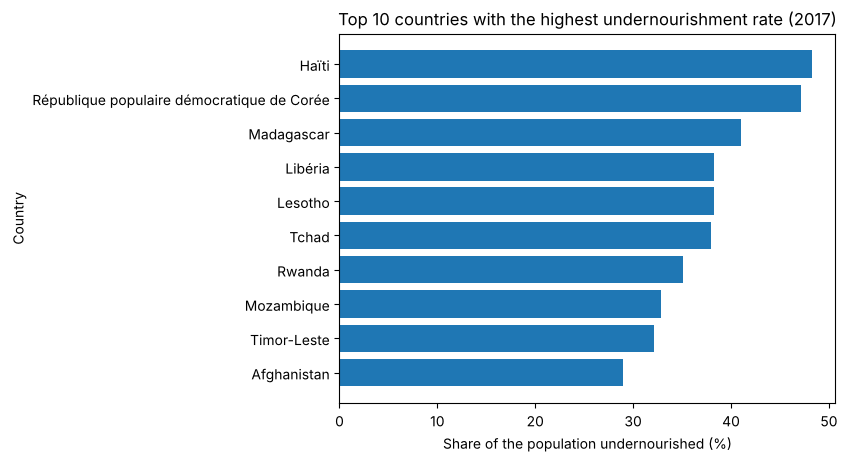

In [66]:
#Creating a horizontal bar chart
top_10_sous_nutrition = population_sous_nutrition_2017_join.nlargest(10, 'Proportion %')
plt.barh(top_10_sous_nutrition['Zone'],
         top_10_sous_nutrition['Proportion %'],
)
plt.xlabel('Share of the population undernourished (%)')
plt.ylabel('Country')
plt.title('Top 10 countries with the highest undernourishment rate (2017)')
plt.gca().invert_yaxis()





Conclusion:
Undernourishment affects almost half of the population in the 3 countries with the most undernourishment in 2017.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.7 - Countries that have received the most food aid since 2013</h3>
</div>

In [67]:
#Computing total food aid per country
aide_par_pays = aide_alimentaire.groupby('Zone')['Aide alimentaire'].sum().reset_index()
aide_par_pays.head(5)

,Zone,Aide alimentaire
0,Afghanistan,185452000
1,Algérie,81114000
2,Angola,5014000
3,Bangladesh,348188000
4,Bhoutan,2666000


In [68]:
#Displaying, after sorting, the 10 countries that received the most food aid
aide_par_pays = aide_par_pays.sort_values(by='Aide alimentaire', ascending=False)
aide_par_pays.head(10)

,Zone,Aide alimentaire
51,République arabe syrienne,1858943000
75,Éthiopie,1381294000
70,Yémen,1206484000
62,Soudan du Sud,695248000
61,Soudan,669784000
31,Kenya,552836000
3,Bangladesh,348188000
60,Somalie,292678000
54,République démocratique du Congo,288502000
44,Niger,276344000


Conclusion:
7 of the 10 countries that have received the most food aid since 2013 are in Africa.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.8 - Food aid to the 5 countries that received the most, 2013 to 2016</h3>
</div>

In [69]:
#Creating a dataframe with the zone, the year and the food aid, then a groupby on zone and year
#Displaying the new dataframe
aide_alimentaire_année_grouped = aide_alimentaire.groupby(['Zone', 'Année'])['Aide alimentaire'].sum().reset_index()
aide_alimentaire_année_grouped.head(5)

,Zone,Année,Aide alimentaire
0,Afghanistan,2013,128238000
1,Afghanistan,2014,57214000
2,Algérie,2013,35234000
3,Algérie,2014,18980000
4,Algérie,2015,17424000


In [70]:
#Filtering between 2013 and 2016
année_2013_2016 = aide_alimentaire_année_grouped[(aide_alimentaire_année_grouped['Année'] >=2013) & (aide_alimentaire_année_grouped['Année'] <=2016)]

In [71]:
#Grouping by zone
année_2013_2016_top5 = année_2013_2016.groupby('Zone')['Aide alimentaire'].sum().reset_index()

In [72]:
#Sorting in descending order
année_2013_2016_top5 = année_2013_2016_top5.sort_values(by='Aide alimentaire', ascending=False)

In [73]:
#Displaying the 5 countries that received the most food aid between 2013 and 2016
année_2013_2016_top5.head(5)


,Zone,Aide alimentaire
51,République arabe syrienne,1858943000
75,Éthiopie,1381294000
70,Yémen,1206484000
62,Soudan du Sud,695248000
61,Soudan,669784000


In [74]:
#Creating a list of the 5 countries that received the most food aid
top_5 = année_2013_2016_top5.head(5)['Zone'].tolist()
print(top_5)


['République arabe syrienne', 'Éthiopie', 'Yémen', 'Soudan du Sud', 'Soudan']


In [75]:
#Filtering the dataframe with our list
aide_alimentaire_top5_filtre = aide_alimentaire_année_grouped[aide_alimentaire_année_grouped['Zone'].isin(top_5)]

In [76]:
#Displaying the countries with their food aid per year
aide_alimentaire_top5_filtre = aide_alimentaire_top5_filtre.sort_values('Année')
print(aide_alimentaire_top5_filtre)

                          Zone  Année  Aide alimentaire
159  République arabe syrienne   2013         563566000
191                     Soudan   2013         330230000
194              Soudan du Sud   2013         196330000
214                      Yémen   2013         264764000
225                   Éthiopie   2013         591404000
215                      Yémen   2014         103840000
192                     Soudan   2014         321904000
160  République arabe syrienne   2014         651870000
226                   Éthiopie   2014         586624000
195              Soudan du Sud   2014         450610000
161  République arabe syrienne   2015         524949000
193                     Soudan   2015          17650000
216                      Yémen   2015         372306000
196              Soudan du Sud   2015          48308000
227                   Éthiopie   2015         203266000
162  République arabe syrienne   2016         118558000
217                      Yémen   2016         46

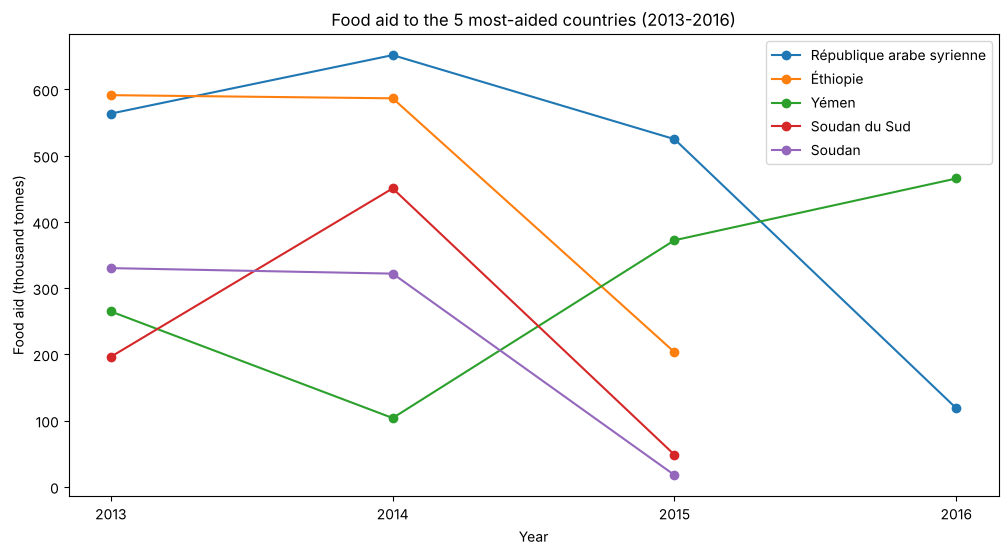

In [77]:
#Creating a line chart to show how the aid received by the most-aided countries changed
plt.figure(figsize=(12, 6))
for pays in top_5:
    data_pays = aide_alimentaire_top5_filtre[aide_alimentaire_top5_filtre['Zone'] == pays]
    plt.plot(data_pays['Année'],
             data_pays['Aide alimentaire'] / 1000000,
             marker='o',
             label=pays)
plt.xlabel('Year')
plt.ylabel('Food aid (thousand tonnes)')
plt.title('Food aid to the 5 most-aided countries (2013-2016)')
plt.legend()
plt.xticks([2013, 2014, 2015, 2016]);

Conclusion: 
4 of the 5 countries that received the most food aid between 2013 and 2016 saw their aid fall considerably from 2015 (2016 for Syria). Ethiopia, Sudan and South Sudan have no record at all in 2016. Yemen, after a drop in 2014, saw its food aid grow again from 2015. We can therefore conclude that world aid was redirected towards Yemen from 2015.


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.9 - Countries with the lowest food availability per person</h3>
</div>

In [78]:
#Computing the kcal available per person per day for each country
dispo_kcal_personne_jour_pays = dispo_alimentaire.groupby('Zone')['Disponibilité alimentaire (Kcal/personne/jour)'].sum().reset_index()

In [79]:
#Displaying the 10 countries with the lowest food availability per person
dispo_kcal_personne_jour_pays = dispo_kcal_personne_jour_pays.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=True)
dispo_kcal_personne_jour_pays.head(10)

,Zone,Disponibilité alimentaire (Kcal/personne/jour)
128,République centrafricaine,1879.0
166,Zambie,1924.0
91,Madagascar,2056.0
0,Afghanistan,2087.0
65,Haïti,2089.0
133,République populaire démocratique de Corée,2093.0
151,Tchad,2109.0
167,Zimbabwe,2113.0
114,Ouganda,2126.0
172,Éthiopie,2129.0


In [80]:
#Computing the average food availability of the 10 countries with the lowest availability per person per day
top_10_pauvres = dispo_kcal_personne_jour_pays.nsmallest(10, 'Disponibilité alimentaire (Kcal/personne/jour)')
moyenne_top_10_pauvres = top_10_pauvres['Disponibilité alimentaire (Kcal/personne/jour)'].mean()
deficit_moyen_pauvres = calorie_moy-moyenne_top_10_pauvres
deficit_moyen_pauvres = round(deficit_moyen_pauvres)
print(f"Average availability of the 10 countries with the lowest food availability per person per day: {moyenne_top_10_pauvres:.0f} kcal/day")
print(f"FAO recommended threshold: {calorie_moy} kcal/person/day")
print(f"Average deficit: {calorie_moy - moyenne_top_10_pauvres:.0f} kcal/person/day")

Average availability of the 10 countries with the lowest food availability per person per day: 2060 kcal/day
FAO recommended threshold: 2400 kcal/person/day
Average deficit: 340 kcal/person/day


Conclusion:
7 of the 10 countries with the lowest availability per person are in Africa. The average calorie deficit per person per day of these 10 countries is 340 kcal.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.10 - Countries with the highest food availability per person</h3>
</div>

In [81]:
#Displaying the 10 countries with the highest food availability per person
dispo_kcal_personne_jour_pays = dispo_kcal_personne_jour_pays.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=False)
dispo_kcal_personne_jour_pays.head(10)

,Zone,Disponibilité alimentaire (Kcal/personne/jour)
11,Autriche,3770.0
16,Belgique,3737.0
159,Turquie,3708.0
171,États-Unis d'Amérique,3682.0
74,Israël,3610.0
72,Irlande,3602.0
75,Italie,3578.0
89,Luxembourg,3540.0
168,Égypte,3518.0
4,Allemagne,3503.0


In [82]:
#Computing the average food availability of the 10 countries with the highest availability per person per day
top_10_riches = dispo_kcal_personne_jour_pays.nlargest(10, 'Disponibilité alimentaire (Kcal/personne/jour)')
moyenne_top_10_riches = top_10_riches['Disponibilité alimentaire (Kcal/personne/jour)'].mean()
surplus_moyen_riches = moyenne_top_10_riches-calorie_moy
surplus_moyen_riches = round(surplus_moyen_riches)
print(f"Average availability of the 10 countries with the highest food availability per person per day: {moyenne_top_10_riches:.0f} kcal/day")
print(f"FAO recommended threshold: {calorie_moy} kcal/person/day")
print(f"Average surplus: {moyenne_top_10_riches-calorie_moy:.0f} kcal/person/day")

Average availability of the 10 countries with the highest food availability per person per day: 3625 kcal/day
FAO recommended threshold: 2400 kcal/person/day
Average surplus: 1225 kcal/person/day


In [83]:
ecart_surplus_deficit = surplus_moyen_riches/deficit_moyen_pauvres
print(f"The calorie surplus of the top 10 by availability per person is {ecart_surplus_deficit:.2f} times the deficit of the bottom 10")

The calorie surplus of the top 10 by availability per person is 3.60 times the deficit of the bottom 10


Conclusion:
The top 10 consume well beyond a human being's calorie needs, with on average 1,225 calories more than the FAO recommendations. Just as the countries with the lowest availability per person are concentrated on one continent, so are those with the highest: more than half of them are in Europe.
This comparison highlights a glaring imbalance in world food distribution and the impact of overconsumption. If the countries with the highest availability per person consumed "more normally", following the FAO recommendations, several million people could get out of food insecurity. The surplus of one "rich" person could cover the deficit of 3.6 "poor" people.
One group's waste could feed the other's hunger.

Caution: this is a theoretical study that does not take into account logistical (storage and transport), political and economic challenges.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.11 - Thailand and cassava</h3>
</div>

In [84]:
#Creating a dataframe with Thailand only
Thailande = dispo_alimentaire_population_2017_join[dispo_alimentaire_population_2017_join['Zone'] == 'Thaïlande'].copy()
Thailande.head(5)

,Zone,Année,Population,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),...,Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock,kcal par pays
14364,Thaïlande,2017,69209810,Abats Comestible,animale,0.0,0.0,3.0,1.11,0.09,...,74000.0,5000.0,33000.0,75000.0,0.0,45000.0,0.0,0.0,0.0,7.578474e+10
14365,Thaïlande,2017,69209810,"Agrumes, Autres",vegetale,0.0,0.0,0.0,0.09,0.00,...,8000.0,6000.0,2000.0,6000.0,0.0,12000.0,0.0,2000.0,0.0,0.000000e+00
14366,Thaïlande,2017,69209810,"Alcool, non Comestible",vegetale,0.0,358000.0,0.0,0.00,0.00,...,358000.0,110000.0,21000.0,0.0,0.0,447000.0,0.0,0.0,0.0,0.000000e+00
14367,Thaïlande,2017,69209810,Aliments pour enfants,vegetale,0.0,0.0,2.0,0.18,0.01,...,12000.0,7000.0,19000.0,12000.0,0.0,0.0,0.0,0.0,0.0,5.052316e+10
14368,Thaïlande,2017,69209810,Ananas,vegetale,0.0,0.0,10.0,10.02,0.04,...,782000.0,1449000.0,9000.0,671000.0,110000.0,2209000.0,0.0,0.0,13000.0,2.526158e+11


In [85]:
#Computing undernourishment in Thailand
thailande = population_sous_nutrition_2017_join[population_sous_nutrition_2017_join['Zone'] == 'Thaïlande']
proportion_thailande = thailande['Proportion %'].values[0]
print(f"In 2017, {proportion_thailande:.2f} % of the population of Thailand was undernourished.")

In 2017, 8.96 % of the population of Thailand was undernourished.


In [86]:
#Displaying Thailand's cassava exports
exportation_manioc_thailande = Thailande[Thailande['Produit'] == 'Manioc']['Exportations - Quantité'].values[0]
print(f"Thailand exported {exportation_manioc_thailande/1000:,.0f} thousand tonnes of cassava in 2017.")

Thailand exported 25,214 thousand tonnes of cassava in 2017.


In [87]:
#Displaying Thailand's cassava imports
importation_manioc_thailande = Thailande[Thailande['Produit'] == 'Manioc']['Importations - Quantité'].values[0]
print(f"Thailand imported {importation_manioc_thailande/1000:,.0f} thousand tonnes of cassava in 2017.")

Thailand imported 1,250 thousand tonnes of cassava in 2017.


Conclusion:
The way Thailand handles cassava turns out to be highly paradoxical. As the figures show, despite large exports of 25.2 million tonnes of cassava, the country still imported 1.25 million tonnes. This poor management of its resources highlights a finding that very likely applies to many other countries, where commercial logic sometimes prevails over food logic, potentially at the expense of local food security. An imported product will naturally not cost the same as a product grown locally. This makes imported food more expensive, and therefore harder to access for the most vulnerable people.

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 6 - Further analyses</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">4 - Undernourishment vs food aid in 2014</h3>
</div>

In [88]:
#Joining population and undernourishment for the year 2014
#Creating the undernourishment share column
#Displaying the 5 countries with the highest undernourishment rate in 2014
sous_nutrition_2014 = sous_nutrition[sous_nutrition['Année'] == '2013-2015']
population_2014 = population[population['Année'] == 2014]
population_sous_nutrition_2014_join = pd.merge(population_2014, sous_nutrition_2014, on='Zone', how='inner')
population_sous_nutrition_2014_join['Proportion %'] = (
    population_sous_nutrition_2014_join['Sous nutrition']
    / population_sous_nutrition_2014_join['Population']
    *100
)
population_sous_nutrition_2014_join = population_sous_nutrition_2014_join.sort_values(by='Proportion %', ascending=False)
population_sous_nutrition_2014_join.head(5)

,Zone,Année_x,Population,Année_y,Sous nutrition,Proportion %
78,Haïti,2014,10549008,2013-2015,5100000,48.345778
157,République populaire démocratique de Corée,2014,25057790,2013-2015,10800000,43.100369
108,Madagascar,2014,23589888,2013-2015,8700000,36.880209
103,Libéria,2014,4359505,2013-2015,1600000,36.701414
183,Tchad,2014,13663566,2013-2015,5000000,36.593668


In [89]:
# #Displaying the 5 countries that received the most food aid in 2014
aide_alimentaire_2014 = aide_alimentaire[aide_alimentaire['Année'] == 2014]
aide_alimentaire_2014 = aide_alimentaire_2014.groupby('Zone')['Aide alimentaire'].sum().reset_index()
aide_alimentaire_2014 = aide_alimentaire_2014.sort_values(by='Aide alimentaire', ascending=False)
aide_alimentaire_2014.head(5)

,Zone,Aide alimentaire
50,République arabe syrienne,651870000
69,Éthiopie,586624000
61,Soudan du Sud,450610000
60,Soudan,321904000
30,Kenya,217418000


Conclusion:
This comparison reveals a striking finding: none of the countries with the highest undernourishment rates is among the countries that received the most food aid in 2014. We can therefore conclude that the distribution of food aid does not necessarily depend on a country's undernourishment rate, but on other factors. This raises questions about the criteria used to allocate food aid, so that they take better account of the real nutritional needs of the most vulnerable.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">5 - World food aid over time (2013-2016)</h3>
</div>

In [90]:
#Computing total food aid for each year
aide_alimentaire_année_mondiale = aide_alimentaire_année_grouped.groupby(['Année'])['Aide alimentaire'].sum().reset_index()
aide_alimentaire_année_mondiale.head(4)

,Année,Aide alimentaire
0,2013,4165674000
1,2014,3939152000
2,2015,2187507000
3,2016,743568000


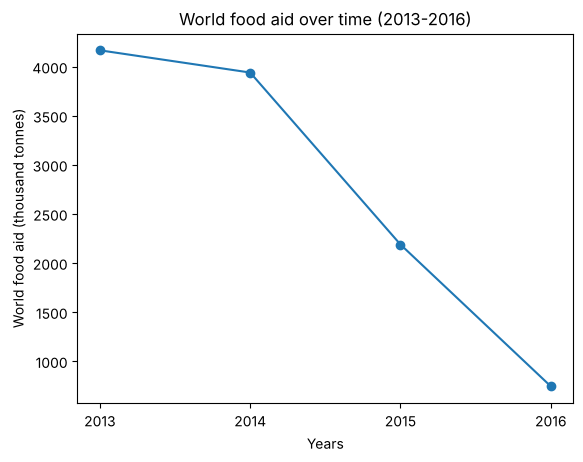

In [91]:
# Creating a line chart
plt.figure()
plt.plot(aide_alimentaire_année_mondiale['Année'],
         aide_alimentaire_année_mondiale['Aide alimentaire']/1000000,
         marker='o',)
plt.xlabel('Years')
plt.xticks(aide_alimentaire_année_mondiale['Année'].astype(int))
plt.ylabel('World food aid (thousand tonnes)')
plt.title('World food aid over time (2013-2016)');

In [92]:
aide_alimentaire_mondiale_2013 = 4165674000
aide_alimentaire_mondiale_2016 = 743568000
baisse_aide_alimentaire = ((aide_alimentaire_mondiale_2013-aide_alimentaire_mondiale_2016)/aide_alimentaire_mondiale_2013)*100
print(f"World food aid fell by {baisse_aide_alimentaire:.2f} % between 2013 and 2016.")

World food aid fell by 82.15 % between 2013 and 2016.


Conclusion:
World food aid fell drastically from 2013 to 2016. It went from 4,166 to 744 thousand tonnes, a drop of 82%. This collapse of food aid in three years raises questions about the reasons for such a significant reduction by the international community.
This sharp drop has consequences for the people in need. In a context of food abundance in some countries, how can aid to the poorest collapse so drastically?